# Krahasimi i modeleve, pasiguria dhe metodologjia

**Lënda:** Machine Learning in Physics  
**Mjedisi:** Python, NumPy, pandas, Matplotlib dhe scikit-learn  
**Roli i notebook-ut:** mjeti kryesor i punës gjatë orës; leksioni i shkruar shërben për thellim teorik.

Në praktikë, problemi nuk mbaron kur një model “punon”. Shpesh disa modele japin rezultate të ngjashme dhe duhet të vendosim mbi bazën e **stabilitetit, kostos, interpretueshmërisë, kalibrimit dhe robustësisë**. Ky laborator trajton nxënien automatike si metodologji shkencore, jo si konkurs algoritmesh.

Për këtë temë do t'u përgjigjemi sidomos tri pyetjeve:

1. Cila metrikë përputhet me pyetjen shkencore?
2. Sa i qëndrueshëm është rezultati ndaj ndarjes së të dhënave?
3. A mbetet modeli i besueshëm kur të dhënat perturbrohen?

Ritmi i punës është: **parashiko → formulo matematikisht → implemento → ekzekuto → mat → interpreto → provo ta prishësh modelin**. Qelizat nuk duhen ekzekutuar mekanikisht njëra pas tjetrës. Para çdo eksperimenti duhet të kemi një pritshmëri dhe pas tij duhet të shpjegojmë mekanizmin që prodhoi rezultatin.


## Organizimi i seancës

| Koha | Veprimtaria | Rezultati i pritshëm |
|---:|---|---|
| 0–10 min | Pyetja shkencore dhe formulimi matematikor | Kuptimi i objektit që po modelojmë |
| 10–25 min | Zbatimi nga parimet e para | Lidhja ndërmjet formulës dhe algoritmit |
| 25–40 min | Eksperimenti numerik dhe figurat diagnostike | Kontrolli i sjelljes së modelit |
| 40–50 min | Krahasimi me implementimin profesional | Verifikimi i zbatimit dhe praktikës së mirë |
| 50–60 min | Interpretimi, kufizimet dhe një rast dështimi | Përfundim metodologjik, jo vetëm numerik |
| Pas orës | Punishtja dhe ushtrimet | Ndrysho një parametër, mat efektin dhe shpjego mekanizmin |

Kjo tabelë është orientuese. Nëse një diskutim fizik ose matematik është i frytshëm, është më e vlefshme të ndalemi te ai sesa të “mbarojmë” notebook-un.


## Rezultatet e të nxënit

Në fund të punës studenti duhet të jetë në gjendje të:

- Krahasoj modele me protokoll identik.
- Raportoj variacionin ndër fold-e.
- Përdor bootstrap.
- Analizoj robustësinë ndaj zhurmës.
- Argumentoj zgjedhjen e modelit sipas kontekstit.


### Para se të ekzekutojmë: Mjedisi llogaritës dhe riprodhueshmëria

Ngarkojmë bibliotekat që do të përdoren dhe fiksojmë `RANDOM_STATE = 42`. Ky seed nuk e bën problemin determinist në kuptimin fizik; ai thjesht na lejon të përsërisim të njëjtin eksperiment llogaritës dhe të diskutojmë metodën pa u hutuar nga ndryshime të rastësishme të mostrës.

**Parashikim para ekzekutimit.** Vlerësoni rendin e madhësisë dhe drejtimin e rezultatit përpara se ta llogarisë kompjuteri.


In [1]:
# Qëllimi i këtij blloku: Mjedisi llogaritës dhe riprodhueshmëria.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import numpy as np
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import pandas as pd
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import matplotlib.pyplot as plt
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from pathlib import Path
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import time

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("10 — Krahasimi i modeleve dhe pasiguria")
print("Seed:", RANDOM_STATE)

10 — Krahasimi i modeleve dhe pasiguria
Seed: 42


**Interpretim.** Një dalje numerike merr kuptim vetëm pasi krahasohet me shkallën e problemit, pritshmërinë teorike dhe një kontroll të pavarur kur është e mundur.


# 1. Dataset i përbashkët: sinjal/sfond — CORE

### Para se të ekzekutojmë: Një dataset i vetëm për të gjithë modelet

Për krahasim të ndershëm duhet të mbajmë të pandryshuar problemin. Krijojmë një dataset me tre veçori dhe dy klasa, me mbivendosje të mjaftueshme që modelet të kenë kompromis real.

**Parashikim para ekzekutimit.** Para se të gjenerohen të dhënat, identifikoni strukturën që është futur në modelin sintetik dhe cilën pjesë ia lëmë zhurmës.


In [2]:
# Qëllimi i këtij blloku: Një dataset i vetëm për të gjithë modelet.
n=1400
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
X0=rng.normal([0,0,0],[1.0,1.1,0.8],size=(900,3))
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
X1=rng.normal([1.25,1.0,0.8],[0.95,0.9,0.85],size=(500,3))
X=np.vstack([X0,X1]); y=np.r_[np.zeros(len(X0)),np.ones(len(X1))]
df=pd.DataFrame(X,columns=["amplitude","width","skew"])
df["target"]=y
df.head()

,amplitude,width,skew,target
0,0.304717,-1.143983,0.600361,0.0
1,0.940565,-2.146139,-1.041744,0.0
2,0.127840,-0.347867,-0.013441,0.0
3,-0.853044,0.967338,0.622234,0.0
4,0.066031,1.239965,0.374007,0.0


### Para se të ekzekutojmë: Inspektimi para benchmark-ut

Para tabelave të score-ve shohim strukturën në dy veçori. Kjo na jep një intuitë se pse modele lineare dhe jolineare mund të sillen ndryshe.

**Parashikim para ekzekutimit.** Vendosni çfarë forme duhet të ketë figura nëse argumenti teorik është i saktë. Grafiku përdoret për të testuar një pritshmëri, jo vetëm për ta ilustruar.


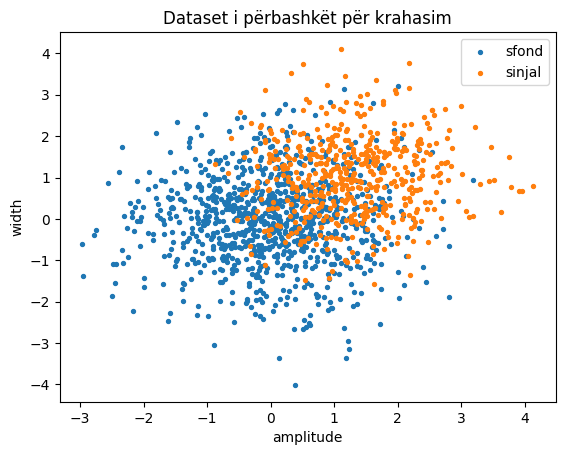

In [3]:
# Qëllimi i këtij blloku: Inspektimi para benchmark-ut.
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.scatter(X[y==0,0],X[y==0,1],s=8,label="sfond")
ax.scatter(X[y==1,0],X[y==1,1],s=8,label="sinjal")
ax.set_xlabel("amplitude"); ax.set_ylabel("width"); ax.legend()
ax.set_title("Dataset i përbashkët për krahasim")
plt.show()

**Interpretim.** Figura duhet lexuar si test i një hipoteze të vogël: a përputhet forma e vëzhguar me atë që parashikuam nga matematika?


# 2. Protokoll i përbashkët — CORE

### Para se të ekzekutojmë: Protokolli i përbashkët

Çdo model merr të njëjtin train/test split dhe të njëjtin cross-validation. Modelet që varen nga distancat ose margjinat futen në pipeline me standardizim; pemët jo. Kjo është pjesë e drejtësisë së krahasimit.

**Parashikim para ekzekutimit.** Cilat statistika duhet të mësohen vetëm nga trajnimi? Parashikoni çfarë rrezikojmë nëse standardizimi ose një transformim tjetër sheh edhe test set-in.


In [4]:
# Qëllimi i këtij blloku: Protokolli i përbashkët.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.pipeline import make_pipeline
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.preprocessing import StandardScaler
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.linear_model import LogisticRegression
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.neighbors import KNeighborsClassifier
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.tree import DecisionTreeClassifier
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.ensemble import RandomForestClassifier
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.svm import SVC

# Ndajmë të dhënat në mënyrë të riprodhueshme; test-i nuk përdoret për trajnim.
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.25,stratify=y,random_state=RANDOM_STATE)
models={
    "LogReg": make_pipeline(StandardScaler(),LogisticRegression(max_iter=3000)),
    "kNN": make_pipeline(StandardScaler(),KNeighborsClassifier(11)),
    "Tree": DecisionTreeClassifier(max_depth=5,random_state=RANDOM_STATE),
    "RF": RandomForestClassifier(n_estimators=250,random_state=RANDOM_STATE),
    "SVM": make_pipeline(StandardScaler(),SVC(C=2,probability=True,random_state=RANDOM_STATE))
}

# 3. Validim i kryqëzuar me disa metrika — CORE

### Para se të ekzekutojmë: Shumë metrika, jo një numër i vetëm

Llogarisim accuracy, precision, recall, F1 dhe AUC. Çdo metrikë përgjigjet ndaj një pyetjeje tjetër, prandaj një model mund të renditet ndryshe sipas kriterit.

**Parashikim para ekzekutimit.** Nuk presim që të gjitha fold-et të japin të njëjtën vlerë. Parashikoni nëse variacioni do të jetë i vogël apo i madh dhe çfarë do të nënkuptonte secili rast.


In [5]:
# Qëllimi i këtij blloku: Shumë metrika, jo një numër i vetëm.
cv=StratifiedKFold(5,shuffle=True,random_state=RANDOM_STATE)
rows=[]
for name,m in models.items():
    # Vlerësojmë modelin në disa ndarje për të matur si performancën ashtu edhe ndryshueshmërinë.
    r=cross_validate(m,Xtr,ytr,cv=cv,scoring=["accuracy","precision","recall","f1","roc_auc"],return_train_score=True)
    rows.append({
        "model":name,
        "acc":r["test_accuracy"].mean(),
        "precision":r["test_precision"].mean(),
        "recall":r["test_recall"].mean(),
        "f1":r["test_f1"].mean(),
        "auc":r["test_roc_auc"].mean(),
        "auc_std":r["test_roc_auc"].std(),
        "fit_time":r["fit_time"].mean()
    })
results=pd.DataFrame(rows).set_index("model")
results

,acc,precision,recall,f1,auc,auc_std,fit_time
model,,,,,,,
LogReg,0.832381,0.781825,0.736000,0.758091,0.915200,0.017354,0.002359
kNN,0.824762,0.763405,0.741333,0.751390,0.898281,0.011542,0.001442
Tree,0.820000,0.764727,0.722667,0.740208,0.880968,0.009253,0.001821
RF,0.825714,0.772839,0.728000,0.748712,0.899269,0.016623,0.290216
SVM,0.823810,0.784327,0.701333,0.739846,0.893649,0.017121,0.034496


### Para se të ekzekutojmë: Pamja e përmbledhur

Grafiku krahasues na ndihmon të shohim shpejt trade-off-et. Ai nuk duhet përdorur për të fshehur devijimet standarde ose paqartësinë e estimimit.

**Parashikim para ekzekutimit.** Vendosni çfarë forme duhet të ketë figura nëse argumenti teorik është i saktë. Grafiku përdoret për të testuar një pritshmëri, jo vetëm për ta ilustruar.


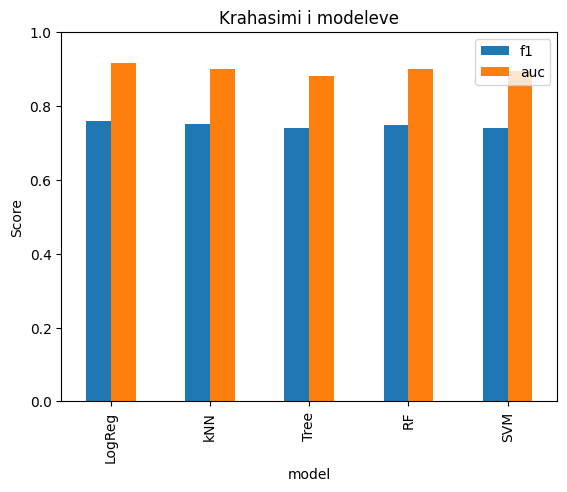

In [6]:
# Qëllimi i këtij blloku: Pamja e përmbledhur.
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
results[["f1","auc"]].plot(kind="bar",ax=ax)
ax.set_ylim(0,1); ax.set_ylabel("Score")
ax.set_title("Krahasimi i modeleve")
plt.show()

**Interpretim.** Figura duhet lexuar si test i një hipoteze të vogël: a përputhet forma e vëzhguar me atë që parashikuam nga matematika?


# 4. Shpërndarja e score-ve ndër fold-e — CORE

### Para se të ekzekutojmë: Stabiliteti ndër fold-e

Boxplot-i tregon jo vetëm mesataren, por edhe sa ndryshon rezultati me ndarjen. Një model pak më i mirë në mesatare por shumë i paqëndrueshëm mund të jetë zgjedhje më e dobët shkencore.

**Parashikim para ekzekutimit.** Nuk presim që të gjitha fold-et të japin të njëjtën vlerë. Parashikoni nëse variacioni do të jetë i vogël apo i madh dhe çfarë do të nënkuptonte secili rast.


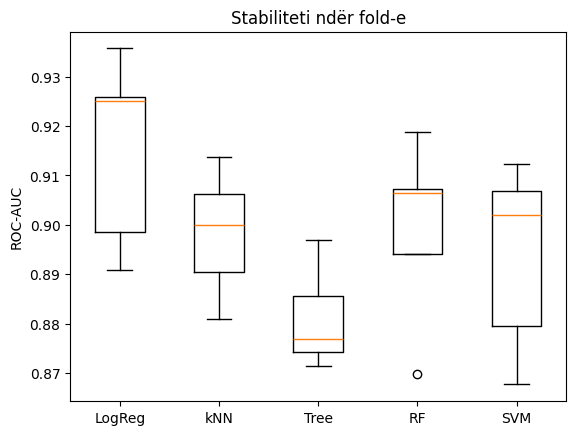

In [7]:
# Qëllimi i këtij blloku: Stabiliteti ndër fold-e.
auc_samples={}
for name,m in models.items():
    # Vlerësojmë modelin në disa ndarje për të matur si performancën ashtu edhe ndryshueshmërinë.
    r=cross_validate(m,Xtr,ytr,cv=cv,scoring="roc_auc")
    auc_samples[name]=r["test_score"]
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.boxplot([auc_samples[k] for k in auc_samples],tick_labels=list(auc_samples))
ax.set_ylabel("ROC-AUC"); ax.set_title("Stabiliteti ndër fold-e")
plt.show()

**Interpretim.** Mesatarja tregon performancën tipike, ndërsa shpërndarja ndër fold-e tregon stabilitetin. Raportimi i vetëm mesatares fsheh një pjesë të pasigurisë metodologjike.


# 5. Test final i paprekur — CORE

### Para se të ekzekutojmë: Shumë metrika, jo një numër i vetëm

Llogarisim accuracy, precision, recall, F1 dhe AUC. Çdo metrikë përgjigjet ndaj një pyetjeje tjetër, prandaj një model mund të renditet ndryshe sipas kriterit.

**Parashikim para ekzekutimit.** Mendoni si duhet të lëvizë TPR kur pranojmë më shumë background. Një kurbë e mirë duhet të ngrihet drejt këndit sipër-majtas, por kjo ende nuk zgjedh pragun operacional.


In [8]:
# Qëllimi i këtij blloku: Shumë metrika, jo një numër i vetëm.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.metrics import roc_auc_score, f1_score
test_rows=[]
for name,m in models.items():
    # Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
    m.fit(Xtr,ytr)
    # Llogarisim parashikimet mbi të dhëna që nuk përdoren për të ndryshuar parametrat e modelit.
    pred=m.predict(Xte)
    # Llogarisim parashikimet mbi të dhëna që nuk përdoren për të ndryshuar parametrat e modelit.
    proba=m.predict_proba(Xte)[:,1]
    test_rows.append((name,f1_score(yte,pred),roc_auc_score(yte,proba)))
pd.DataFrame(test_rows,columns=["model","F1_test","AUC_test"]).set_index("model")

,F1_test,AUC_test
model,,
LogReg,0.791489,0.919787
kNN,0.769874,0.903982
Tree,0.784314,0.904231
RF,0.773663,0.896818
SVM,0.801688,0.890240


**Interpretim.** ROC mat aftësinë renditëse përgjatë të gjitha pragjeve. AUC e përmbledh këtë në një numër, por nuk përcakton pragun që duhet përdorur në eksperiment.


---
## Deri këtu: materiali bazë për orën mësimore

Në një seancë rreth 60 minuta, zakonisht ndalemi këtu. Seksionet që vijojnë janë për thellim,
ushtrime të pavarura dhe eksperimentim.

# 6. Sensitivitet ndaj zhurmës — EXTENDED

### Para se të ekzekutojmë: Robustësia ndaj perturbimeve

Shtojmë zhurmë të kontrolluar në veçori dhe masim degradimin e performancës. Ky test është shumë relevant në fizikë, sepse instrumentet reale kanë pacaktueshmëri dhe drift.

**Parashikim para ekzekutimit.** Vendosni çfarë forme duhet të ketë figura nëse argumenti teorik është i saktë. Grafiku përdoret për të testuar një pritshmëri, jo vetëm për ta ilustruar.


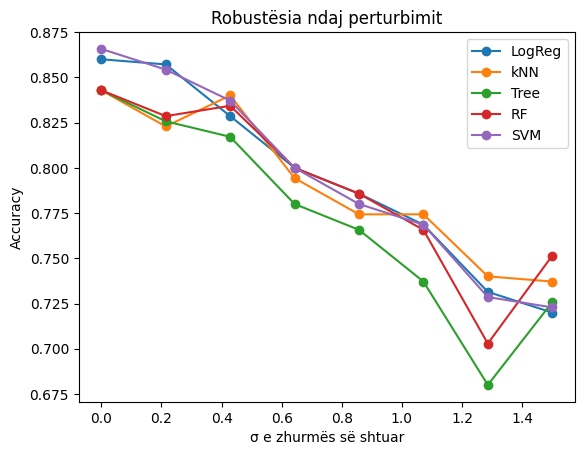

In [9]:
# Qëllimi i këtij blloku: Robustësia ndaj perturbimeve.
noise_levels=np.linspace(0,1.5,8)
curves={name:[] for name in models}
for sig in noise_levels:
    # Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
    Xnoisy=Xte+rng.normal(0,sig,Xte.shape)
    for name,m in models.items():
        curves[name].append(m.score(Xnoisy,yte))
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
for name,vals in curves.items():
    ax.plot(noise_levels,vals,marker="o",label=name)
ax.set_xlabel("σ e zhurmës së shtuar"); ax.set_ylabel("Accuracy")
ax.legend(); ax.set_title("Robustësia ndaj perturbimit")
plt.show()

**Interpretim.** Figura duhet lexuar si test i një hipoteze të vogël: a përputhet forma e vëzhguar me atë që parashikuam nga matematika?


# 7. Bootstrap i AUC — EXTENDED

### Para se të ekzekutojmë: Bootstrap i metrikës

Rimostrojmë test set-in për të krijuar një shpërndarje të AUC. Kështu një score i vetëm shndërrohet në një vlerësim me pacaktueshmëri.

**Parashikim para ekzekutimit.** Mendoni si duhet të lëvizë TPR kur pranojmë më shumë background. Një kurbë e mirë duhet të ngrihet drejt këndit sipër-majtas, por kjo ende nuk zgjedh pragun operacional.


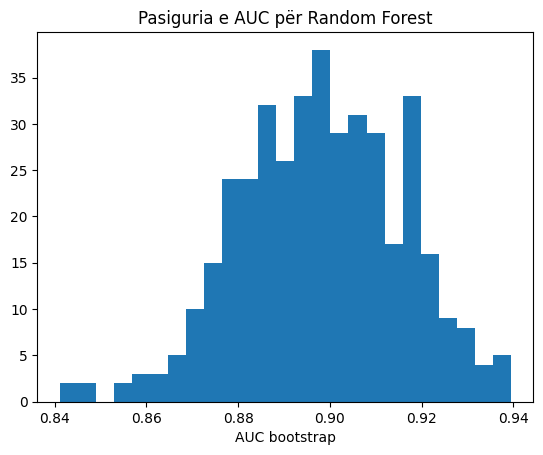

In [10]:
# Qëllimi i këtij blloku: Bootstrap i metrikës.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.utils import resample
# Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
rf=models["RF"].fit(Xtr,ytr)
# Llogarisim parashikimet mbi të dhëna që nuk përdoren për të ndryshuar parametrat e modelit.
p=rf.predict_proba(Xte)[:,1]
boot=[]
# Përsërisim procedurën për të studiuar konvergjencën ose ndjeshmërinë ndaj parametrave.
for _ in range(400):
    idx=rng.integers(0,len(yte),len(yte))
    if len(np.unique(yte[idx]))<2: continue
    boot.append(roc_auc_score(yte[idx],p[idx]))
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.hist(boot,bins=25)
ax.set_xlabel("AUC bootstrap"); ax.set_title("Pasiguria e AUC për Random Forest")
plt.show()

**Interpretim.** ROC mat aftësinë renditëse përgjatë të gjitha pragjeve. AUC e përmbledh këtë në një numër, por nuk përcakton pragun që duhet përdorur në eksperiment.


# 8. Learning curves — EXTENDED

### Para se të ekzekutojmë: A kemi nevojë për më shumë të dhëna?

Learning curve tregon si ndryshon performanca me madhësinë e trajnimit. Nëse train dhe validation janë të dy të dobët dhe të afërt, problemi është më shumë bias; nëse ka hendek të madh, kemi shenjë variance.

**Parashikim para ekzekutimit.** Mendoni si duhet të lëvizë TPR kur pranojmë më shumë background. Një kurbë e mirë duhet të ngrihet drejt këndit sipër-majtas, por kjo ende nuk zgjedh pragun operacional.


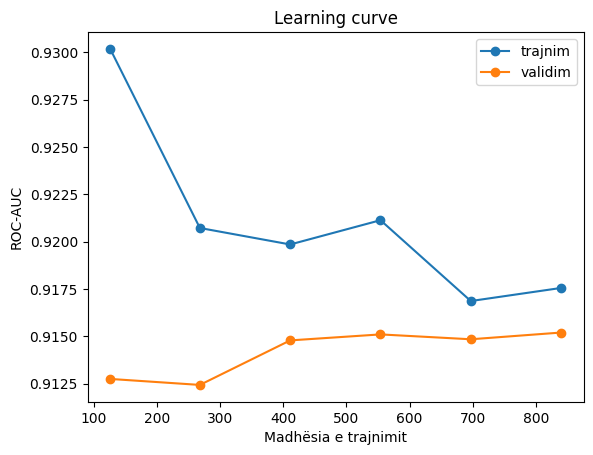

In [11]:
# Qëllimi i këtij blloku: A kemi nevojë për më shumë të dhëna?.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.model_selection import learning_curve
sizes,tr,va=learning_curve(models["LogReg"],Xtr,ytr,cv=cv,scoring="roc_auc",
                            train_sizes=np.linspace(0.15,1.0,6))
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.plot(sizes,tr.mean(axis=1),marker="o",label="trajnim")
ax.plot(sizes,va.mean(axis=1),marker="o",label="validim")
ax.set_xlabel("Madhësia e trajnimit"); ax.set_ylabel("ROC-AUC")
ax.legend(); ax.set_title("Learning curve")
plt.show()

**Interpretim.** ROC mat aftësinë renditëse përgjatë të gjitha pragjeve. AUC e përmbledh këtë në një numër, por nuk përcakton pragun që duhet përdorur në eksperiment.


# 9. Kalibrimi — EXTENDED

### Para se të ekzekutojmë: A kanë kuptim probabilitetet?

Një model mund të rendisë mirë mostrat dhe megjithatë të japë probabilitete të keqkalibruara. Kalibrimi kontrollon nëse, p.sh., ngjarjet me probabilitet 0.7 ndodhin realisht afërsisht 70% të rasteve.

**Parashikim para ekzekutimit.** Nëse modeli thotë “0.8” për shumë raste, afërsisht 80% e tyre duhet të jenë pozitive që probabiliteti të jetë i kalibruar.


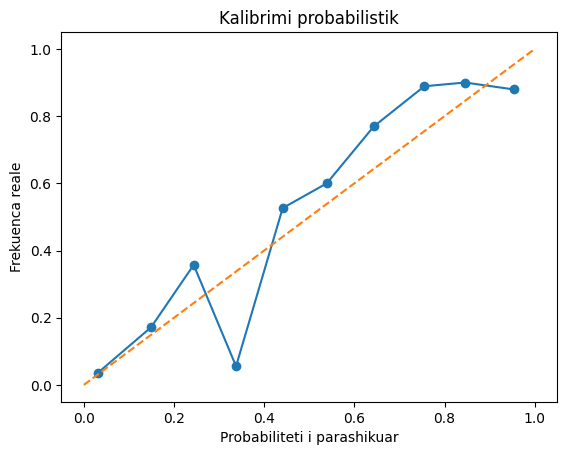

In [12]:
# Qëllimi i këtij blloku: A kanë kuptim probabilitetet?.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.calibration import calibration_curve
# Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
lr=models["LogReg"].fit(Xtr,ytr)
# Llogarisim parashikimet mbi të dhëna që nuk përdoren për të ndryshuar parametrat e modelit.
p=lr.predict_proba(Xte)[:,1]
frac,meanp=calibration_curve(yte,p,n_bins=10)
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.plot(meanp,frac,marker="o")
ax.plot([0,1],[0,1],linestyle="--")
ax.set_xlabel("Probabiliteti i parashikuar"); ax.set_ylabel("Frekuenca reale")
ax.set_title("Kalibrimi probabilistik")
plt.show()

**Interpretim.** Një model mund të rendisë shumë mirë ngjarjet (AUC i lartë) dhe megjithatë të japë probabilitete të kalibruara dobët. Renditja dhe kalibrimi janë dy pyetje të ndryshme.


**Interpretim.** Modeli më i mirë varet nga kriteri: performancë mesatare, stabilitet, kohë, interpretueshmëri, kalibrim dhe robustësi mund të favorizojnë zgjedhje të ndryshme.

Në një analizë reale ky interpretim duhet të shoqërohet me kontroll të njësive, madhësive karakteristike dhe hipotezave që lejojnë kalimin nga një tregues numerik te një përfundim fizik.

## Punishtja — ndrysho, mat dhe shpjego

Në këtë pjesë nuk kërkohet ekzekutim pasiv. Për çdo eksperiment:

1. shkruani paraprakisht çfarë prisni të ndodhë;
2. ndryshoni **vetëm një** element në të njëjtën kohë;
3. ruani metrikën ose figurën që ndryshon;
4. shpjegoni mekanizmin matematik ose statistikor;
5. dalloni qartë atë që tregon eksperimenti nga ajo që **nuk** mund të përfundohet prej tij.

### Pyetje për diskutim

1. Pse nuk ka “model më të mirë” pa specifikuar kriterin?
2. Çfarë dallimi ka uncertainty e score-it nga uncertainty e parashikimit?
3. Pse calibration është e rëndësishme kur probabilitetet përdoren për vendime?
4. Si ndërthuren performanca dhe interpretueshmëria?


# Ushtrime — PLAYGROUND

        ## A. Ushtrime të shkurtra
        1. Renditni modelet sipas F1 dhe sipas AUC; a është renditja e njëjtë?
2. Matni kohën e parashikimit.
3. Krahasoni performancën me dhe pa standardizim.
4. Përdorni permutation importance për RF.

        ## B. Ushtrim i plotë
        Përcaktoni një skenar ku false negatives kushtojnë 5 herë më shumë se false positives dhe zgjidhni modelin/pragun sipas kësaj kostoje.

        ## C. Playground
        Ndryshoni pabalancimin e klasave, zhurmën, metrikën kryesore dhe parametrat.

In [13]:
# TODO / PLAYGROUND
# Ndryshoni parametrat, shtoni grafikë ose krahasoni modele të tjera.

## Përmbledhje konceptuale e kapitullit

Notebook-u **Krahasimi i modeleve dhe pacaktueshmëria** duhet të lihet me një ide të qartë: algoritmi është vetëm një hallkë e arsyetimit. Para tij kemi zgjedhjen e përfaqësimit dhe hipotezat mbi të dhënat; pas tij kemi validimin, diagnostikën dhe interpretimin. Nëse një student mund të ekzekutojë të gjitha qelizat por nuk mund të shpjegojë pse secila prej tyre është e nevojshme, atëherë puna llogaritëse nuk është përfunduar ende.

Për studim të mëtejshëm, rikthehuni te shënimet e leksionit për derivimet e plota dhe përdoreni këtë notebook si laborator ku këto ide testohen numerikisht.

### Zgjidhje orientuese për instruktorin
- Renditja sipas F1 dhe AUC mund të ndryshojë sepse matin aspekte të ndryshme.
- Modeli duhet zgjedhur sipas objektivit shkencor, jo vetëm score-it maksimal.
- Kur kostoja e false negative është më e lartë, pragu duhet optimizuar mbi një funksion kostoje, jo domosdoshmërisht në 0.5.

## Kontrolli përfundimtar

- [ ] Krahasoj modele me protokoll identik.
- [ ] Raportoj variacionin ndër fold-e.
- [ ] Përdor bootstrap.
- [ ] Analizoj robustësinë ndaj zhurmës.
- [ ] Argumentoj zgjedhjen e modelit sipas kontekstit.
